In [1]:
import numpy as np
import pandas as pd
import time
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
import re
from transformers import BertModel, BertTokenizer
import torch
from scipy.stats import skew
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from tabulate import tabulate
import matplotlib.pyplot as plt
import torch.nn.functional as F

[codecarbon WARNING @ 12:44:16] Nvidia GPU detected but pynvml initialization failed. Please ensure NVIDIA drivers are properly installed.


In [6]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(
    "data/ohsumed-all"
)

documents = {}

for category_dir in sorted(DATA_DIR.glob("C*")):
    if not category_dir.is_dir():
        continue

    label = category_dir.name

    for file_path in category_dir.iterdir():
        if not file_path.is_file():
            continue

        document_id = file_path.name

        text = file_path.read_text(
            encoding="latin-1",
            errors="replace",
        ).strip()

        if document_id not in documents:
            documents[document_id] = {
                "document_id": document_id,
                "text": text,
                "labels": set(),
            }

        documents[document_id]["labels"].add(label)


df = pd.DataFrame(documents.values())

# Convert each label set into a sorted list
df["labels"] = df["labels"].apply(
    lambda x: sorted(x)
)

df = (
    df.sort_values("document_id")
    .reset_index(drop=True)
)

print(df.head())
print("Unique documents:", len(df))
print(
    "Unique labels:",
    df["labels"].explode().nunique(),
)
print(
    "Total document-label assignments:",
    df["labels"].str.len().sum(),
)
print(
    "Average labels per document:",
    df["labels"].str.len().mean(),
)

  document_id                                               text      labels
0     0000000  Evaluation of women with possible appendicitis...       [C06]
1     0000001  Cause of death in an emergency department \n A...       [C14]
2     0000002  Treatment of Fournier's gangrene with adjuncti...  [C12, C23]
3     0000003  Intermittent obstruction of an incarcerated hi...       [C06]
4     0000005  Excitatory amino acids in the developing brain...       [C10]
Unique documents: 34389
Unique labels: 23
Total document-label assignments: 56984
Average labels per document: 1.657041495827154


In [7]:
empty_document_ids = (
    df["document_id"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
)

empty_texts = (
    df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
)

print(
    "Empty document IDs:",
    empty_document_ids.sum(),
)

print(
    "Empty texts:",
    empty_texts.sum(),
)

Empty document IDs: 0
Empty texts: 0


In [9]:
df["_text_key"] = (
    df["text"]
    .fillna("")
    .astype(str)
    .str.replace(
        r"\s+",
        " ",
        regex=True,
    )
    .str.strip()
)
duplicate_text_mask = (
    df["_text_key"]
    .duplicated(keep=False)
)

print(
    "Rows with duplicated text:",
    duplicate_text_mask.sum(),
)

print(
    "Number of duplicated text groups:",
    df.loc[
        duplicate_text_mask,
        "_text_key",
    ].nunique(),
)
with pd.option_context(
    "display.max_colwidth",
    200,
):
    display(
        df.loc[
            duplicate_text_mask,
            [
                "document_id",
                "labels",
                "_text_key",
            ],
        ]
        .sort_values("_text_key")
        .head(20)
    )

Rows with duplicated text: 6
Number of duplicated text groups: 3


,document_id,labels,_text_key
33549,0048731,"[C10, C23]","Detection of preclinical Parkinson's disease with PET. Putamen 18F-dopa uptake of patients with Parkinson's disease (PD) is reduced by at least 35% at onset of symptoms; therefore, positron-emissi..."
34332,0050118,"[C10, C23]","Detection of preclinical Parkinson's disease with PET. Putamen 18F-dopa uptake of patients with Parkinson's disease (PD) is reduced by at least 35% at onset of symptoms; therefore, positron-emissi..."
30810,0044187,"[C10, C23]",Electrophysiologic analysis of early Parkinson's disease. We have been interested in the application of quantitative measures of motor performance as a possible means of early detection of Parkins...
31356,0044981,"[C10, C23]",Electrophysiologic analysis of early Parkinson's disease. We have been interested in the application of quantitative measures of motor performance as a possible means of early detection of Parkins...
21523,0030921,"[C10, C23]","Genetic susceptibility to Parkinson's disease. Genetic factors clearly cause Lewy-body Parkinson's disease (PD) in a subset of autosomal-dominant families. However, most cases of PD are sporadic. ..."
30814,0044191,"[C10, C23]","Genetic susceptibility to Parkinson's disease. Genetic factors clearly cause Lewy-body Parkinson's disease (PD) in a subset of autosomal-dominant families. However, most cases of PD are sporadic. ..."


In [11]:
from itertools import chain


def merge_label_lists(label_series):
    return sorted(
        set(
            chain.from_iterable(
                label_series
            )
        )
    )


df = (
    df.groupby(
        "_text_key",
        as_index=False,
    )
    .agg(
        document_id=(
            "document_id",
            "first",
        ),
        text=(
            "text",
            "first",
        ),
        labels=(
            "labels",
            merge_label_lists,
        ),
    )
)
label_type_counts = (
    df["labels"]
    .apply(type)
    .value_counts()
)

print(label_type_counts)

empty_labels = df["labels"].apply(
    lambda x: (
        isinstance(x, list)
        and len(x) == 0
    )
)

print(
    "Documents without labels:",
    empty_labels.sum(),
)

df = df.copy()

# Remove rows with missing essential values
df = df.dropna(
    subset=[
        "document_id",
        "text",
        "labels",
    ]
)

# Minimal text normalization
df["training_text"] = (
    df["text"]
    .astype(str)
    .str.replace(
        r"\s+",
        " ",
        regex=True,
    )
    .str.strip()
)

# Remove empty texts
df = df[
    df["training_text"].ne("")
]

# Ensure sorted and unique labels
df["labels"] = df["labels"].apply(
    lambda labels: sorted(
        set(labels)
    )
)

# Remove empty label rows
df = df[
    df["labels"].str.len() > 0
]

# Remove duplicate document IDs
df = df.drop_duplicates(
    subset=["document_id"],
    keep="first",
)

df = df.reset_index(drop=True)

print("Final shape:", df.shape)

labels
<class 'list'>    34386
Name: count, dtype: int64
Documents without labels: 0
Final shape: (34386, 5)


In [12]:
expected_labels = {
    f"C{i:02d}"
    for i in range(1, 24)
}

observed_labels = set(
    df["labels"]
    .explode()
    .dropna()
    .unique()
)

assert df["document_id"].notna().all()
assert df["document_id"].is_unique

assert df["training_text"].notna().all()
assert df["training_text"].str.len().gt(0).all()

assert df["labels"].notna().all()

assert df["labels"].map(
    lambda x: isinstance(x, list)
).all()

assert df["labels"].str.len().gt(0).all()

assert observed_labels == expected_labels

print("Dataset validation passed.")
print("Documents:", len(df))
print("Observed labels:", sorted(observed_labels))

Dataset validation passed.
Documents: 34386
Observed labels: ['C01', 'C02', 'C03', 'C04', 'C05', 'C06', 'C07', 'C08', 'C09', 'C10', 'C11', 'C12', 'C13', 'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21', 'C22', 'C23']


In [13]:
training_df = df[
    [
        "document_id",
        "training_text",
        "labels",
    ]
].copy()

print(training_df.shape)
display(training_df.head())

(34386, 3)


,document_id,training_text,labels
0,0042801,"""Angioglioma"" and the arteriovenous malformati...",[C04]
1,0042146,"""Beaten to death"". An autopsy series of homici...",[C21]
2,0006344,"""Cloggology"" revisited: endoscopic or surgical...",[C23]
3,0031640,"""Designer drugs""--a current perspective. Since...",[C21]
4,0041071,"""Directed"" emergency room thoracotomy: a progn...",[C21]


In [20]:
TEXT_COL = "training_text"
LABEL_COL = "labels"

SAMPLE_SIZE = 200
RANDOM_SEED = 42
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased"
]

In [10]:
def asymmetry_eta(x, bandwidth=None):
    """
    Estimate eta using Patil et al.-style estimator:
    eta_hat = -Corr(f_hat(X_i), F_hat(X_i))

    f_hat(X_i): leave-one-out Gaussian KDE
    F_hat(X_i): leave-one-out empirical CDF
    """
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)

    if n < 3:
        return np.nan

    # Silverman's bandwidth
    s = np.std(x, ddof=1)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    sigma = min(s, iqr / 1.349) if iqr > 0 else s
    if np.isclose(sigma, 0):
        sigma = s if s > 0 else 1.0
    h = bandwidth if bandwidth is not None else 0.9 * sigma * (n ** (-1 / 5))#calculate bandwidth
    if h <= 0:
        h = 1.06 * (s if s > 0 else 1.0) * (n ** (-1 / 5))

    # Leave-one-out KDE
    diffs = (x[None, :] - x[:, None]) / h#cal culate pairwise difference
    K = stats.norm.pdf(diffs)#fit standardized distance into gaussian kernel
    np.fill_diagonal(K, 0.0)#leave one out
    f_hat = K.sum(axis=1) / ((n - 1) * h)#KED for pdf

    # Leave-one-out empirical CDF
    indicators = (x[None, :] < x[:, None]).astype(float)
    np.fill_diagonal(indicators, 0.0)
    F_hat = indicators.sum(axis=1) / (n - 1)

    if np.std(f_hat, ddof=1) == 0 or np.std(F_hat, ddof=1) == 0:
        return np.nan

    eta = -np.corrcoef(f_hat, F_hat)[0, 1]#calculate correlation

    return eta

In [4]:
def chi2_distance(dist1, dist2, bins=50, value_range=None, eps=1e-12):

    hist1, bin_edges = np.histogram(dist1, bins=bins, range=value_range)
    hist2, _ = np.histogram(dist2, bins=bin_edges)

    p = hist1 / hist1.sum()
    q = hist2 / hist2.sum()

    chi_dist = 0.5 * np.sum((p - q) ** 2 / (p + q + eps))

    return chi_dist

In [5]:
def create_cosine_similarity_matrix(
    embeddings,
):
    normalized_embeddings = F.normalize(
        embeddings.detach().cpu().float(),
        p=2,
        dim=1,
    )

    similarity_matrix = (
        normalized_embeddings
        @ normalized_embeddings.T
    )

    return similarity_matrix.numpy()

In [14]:
from collections import defaultdict
from itertools import combinations

import numpy as np


def convert_to_label_sets(labels):
    label_sets = []

    for document_labels in labels:
        if isinstance(
            document_labels,
            str,
        ):
            label_set = {
                document_labels
            }
        else:
            label_set = set(
                document_labels
            )

        label_sets.append(
            label_set
        )

    return label_sets

In [ ]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        shared_labels = (
            label_sets[first_index]
            .intersection(
                label_sets[second_index]
            )
        )

        # Same-label means at least one
        # shared label.
        if not shared_labels:
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add once to the overall distribution,
        # regardless of how many labels are shared.
        all_scores.append(
            score
        )

        # Per-label diagnostic data.
        # The score can appear in multiple label
        # groups here, but not in all_scores.
        for label in shared_labels:
            scores_by_label[
                label
            ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No within-label document "
            "pairs were found."
        )

    scores_by_label = {
        label: np.asarray(
            label_scores,
            dtype=float,
        )
        for label, label_scores
        in sorted(
            scores_by_label.items()
        )
    }

    print(
        "Total unique within-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label:
        return (
            all_scores,
            scores_by_label,
        )

    return all_scores

In [16]:
def calculate_between_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label_pair=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label_pair = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        first_label_set = (
            label_sets[first_index]
        )

        second_label_set = (
            label_sets[second_index]
        )

        # Different-label means no shared labels.
        if not first_label_set.isdisjoint(
            second_label_set
        ):
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add each document pair exactly once.
        all_scores.append(
            score
        )

        # Store the full label-set pair only
        # for diagnostic purposes.
        first_key = tuple(
            sorted(first_label_set)
        )

        second_key = tuple(
            sorted(second_label_set)
        )

        label_set_pair = tuple(
            sorted(
                (
                    first_key,
                    second_key,
                )
            )
        )

        scores_by_label_pair[
            label_set_pair
        ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No between-label document "
            "pairs were found."
        )

    scores_by_label_pair = {
        label_pair: np.asarray(
            pair_scores,
            dtype=float,
        )
        for label_pair, pair_scores
        in scores_by_label_pair.items()
    }

    print(
        "Number of label-set pair types:",
        len(scores_by_label_pair),
    )

    print(
        "Total unique between-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label_pair:
        return (
            all_scores,
            scores_by_label_pair,
        )

    return all_scores

In [17]:
def prepare_sampling_dataframe(
    training_df,
):
    result = training_df[
        [
            "document_id",
            TEXT_COL,
            LABEL_COL,
        ]
    ].copy()

    # Remove missing essential values
    result = result.dropna(
        subset=[
            "document_id",
            TEXT_COL,
            LABEL_COL,
        ]
    )

    # Remove empty text
    result = result[
        result[TEXT_COL]
        .astype(str)
        .str.strip()
        .ne("")
    ].copy()

    # One row per document
    result = result.drop_duplicates(
        subset=["document_id"],
        keep="first",
    )

    # Character count: descriptive only
    result["char_length"] = (
        result[TEXT_COL]
        .str.len()
    )

    # Word count: used for quantile sampling
    result["length"] = (
        result[TEXT_COL]
        .str.split()
        .str.len()
    )

    result = result.reset_index(
        drop=True
    )

    print(
        "Shape:",
        result.shape,
    )

    print(
        "Minimum word count:",
        result["length"].min(),
    )

    print(
        "Average word count:",
        result["length"].mean(),
    )

    print(
        "Maximum word count:",
        result["length"].max(),
    )

    print(
        "Number of labels:",
        result[LABEL_COL]
        .explode()
        .nunique(),
    )

    return result

In [ ]:
sampling_df = (
    prepare_sampling_dataframe(
        training_df
    )
)

Shape: (34386, 5)
Minimum word count: 24
Average word count: 181.65782585936137
Maximum word count: 596
Number of labels: 23


In [22]:
def sample_from_length_groups(
    df,
    sample_size=200,
    num_quantiles=100,
    random_seed=42,
    text_col="training_text",
):
    sampling_pool = (
        df.copy()
        .reset_index(drop=True)
    )

    if sample_size > len(sampling_pool):
        raise ValueError(
            f"sample_size={sample_size} exceeds "
            f"dataset size={len(sampling_pool)}"
        )

    # Calculate word count if it does not exist
    if "length" not in sampling_pool.columns:
        sampling_pool["length"] = (
            sampling_pool[text_col]
            .astype(str)
            .str.split()
            .str.len()
        )

    # The actual number of groups cannot exceed:
    # 1. requested quantiles
    # 2. sample size
    # 3. number of unique text lengths
    effective_quantiles = min(
        num_quantiles,
        sample_size,
        sampling_pool["length"].nunique(),
    )

    # Create length groups from the whole dataset
    sampling_pool["_length_group"] = pd.qcut(
        sampling_pool["length"],
        q=effective_quantiles,
        labels=False,
        duplicates="drop",
    )

    number_of_groups = (
        sampling_pool["_length_group"]
        .nunique()
    )

    samples_per_group = (
        sample_size // number_of_groups
    )

    sampled_parts = []

    # Sample approximately the same number
    # from every length group
    for group_number, group_df in (
        sampling_pool.groupby(
            "_length_group",
            observed=True,
        )
    ):
        number_to_sample = min(
            samples_per_group,
            len(group_df),
        )

        sampled_part = group_df.sample(
            n=number_to_sample,
            random_state=(
                random_seed
                + int(group_number)
            ),
        )

        sampled_parts.append(
            sampled_part
        )

    sampled_df = pd.concat(
        sampled_parts,
        axis=0,
    )

    # Fill remaining positions if qcut produced
    # fewer groups or some groups were too small
    remaining_count = (
        sample_size - len(sampled_df)
    )

    if remaining_count > 0:
        remaining_pool = (
            sampling_pool.drop(
                index=sampled_df.index
            )
        )

        additional_samples = (
            remaining_pool.sample(
                n=remaining_count,
                random_state=random_seed,
            )
        )

        sampled_df = pd.concat(
            [
                sampled_df,
                additional_samples,
            ],
            axis=0,
        )

    # Shuffle the final sample
    sampled_df = (
        sampled_df
        .sample(
            frac=1,
            random_state=random_seed,
        )
        .drop(
            columns=["_length_group"]
        )
        .reset_index(drop=True)
    )

    print(
        "Original dataset size:",
        len(sampling_pool),
    )
    print(
        "Actual sample size:",
        len(sampled_df),
    )
    print(
        "Minimum word count:",
        sampled_df["length"].min(),
    )
    print(
        "Average word count:",
        sampled_df["length"].mean(),
    )
    print(
        "Maximum word count:",
        sampled_df["length"].max(),
    )
    print(
        "Number of represented labels:",
        sampled_df["labels"]
        .explode()
        .nunique(),
    )

    return sampled_df

In [23]:
sampled_df = sample_from_length_groups(
    df=sampling_df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    random_seed=RANDOM_SEED,
    text_col=TEXT_COL,
)

Original dataset size: 34386
Actual sample size: 200
Minimum word count: 43
Average word count: 182.075
Maximum word count: 404
Number of represented labels: 22


In [24]:
from transformers import (
    AutoTokenizer,
    AutoModel,
)


def compute_embeddings(
    texts,
    model_name,
    batch_size=64,
    max_token=128,
):
    # Auto classes support all seven model checkpoints
    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        use_fast=True,
    )

    model = AutoModel.from_pretrained(
        model_name,
    )

    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    model = model.to(device)
    model.eval()

    all_embeddings = []

    for start_index in range(
        0,
        len(texts),
        batch_size,
    ):
        batch_texts = texts[
            start_index:
            start_index + batch_size
        ]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token,
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            outputs = model(**inputs)

            token_embeddings = (
                outputs.last_hidden_state
            )

            # Shape:
            # attention_mask:
            # [batch_size, sequence_length]
            #
            # expanded_mask:
            # [batch_size, sequence_length, 1]
            expanded_mask = (
                inputs["attention_mask"]
                .unsqueeze(-1)
                .to(token_embeddings.dtype)
            )

            # Sum only real-token embeddings
            summed_embeddings = (
                token_embeddings
                * expanded_mask
            ).sum(dim=1)

            # Number of real tokens in each text
            valid_token_counts = (
                expanded_mask
                .sum(dim=1)
                .clamp(min=1e-9)
            )

            # Masked mean pooling
            batch_embeddings = (
                summed_embeddings
                / valid_token_counts
            )

        all_embeddings.append(
            batch_embeddings.cpu()
        )

    embeddings = torch.cat(
        all_embeddings,
        dim=0,
    )

    print(
        "Model:",
        model_name,
    )
    print(
        "Device:",
        device,
    )
    print(
        "Embedding shape:",
        tuple(embeddings.shape),
    )

    return embeddings

In [25]:
def bootstrap_chi2_from_existing_scores(
    same_scores,
    diff_label,
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):

    rng = np.random.default_rng(random_seed)

    same_scores = np.asarray(same_scores)
    target_size = len(same_scores)

    # same-label statistics, fixed across bootstrap
    same_mean = same_scores.mean()
    same_eta = asymmetry_eta(same_scores, bandwidth=eta_bandwidth)
    same_abs_eta = abs(same_eta)

    label_pairs = list(diff_label.keys())
    n_pair_types = len(label_pairs)

    base_n = target_size // n_pair_types
    remainder = target_size % n_pair_types

    bootstrap_rows = []

    print("Same-label target size:", target_size)
    print("Different-label pair types:", n_pair_types)
    print("Base sample per diff-label pair:", base_n)

    for b in range(n_bootstrap):
        sampled_diff_scores = []

        for k, pair in enumerate(label_pairs):
            # already-computed cosine similarity scores for this label pair
            cosine_scores_for_this_pair = np.asarray(diff_label[pair])

            n_sample = base_n + (1 if k < remainder else 0)

            sampled_cosine_scores = rng.choice(
                cosine_scores_for_this_pair,
                size=n_sample,
                replace=True
            )

            sampled_diff_scores.extend(sampled_cosine_scores)

        sampled_diff_scores = np.asarray(sampled_diff_scores)

        # chi-square distance between same-label and bootstrapped diff-label distributions
        chi2_dist = chi2_distance(
            dist1=same_scores,
            dist2=sampled_diff_scores,
            bins=bins,
            value_range=value_range
        )

        # bootstrap diff-label statistics
        diff_mean = sampled_diff_scores.mean()
        diff_eta = asymmetry_eta(sampled_diff_scores, bandwidth=eta_bandwidth)
        diff_abs_eta = abs(diff_eta)

        mean_gap = same_mean - diff_mean
        abs_mean_gap = abs(mean_gap)

        eta_gap = same_eta - diff_eta
        abs_eta_gap = abs(eta_gap)

        chi2_result = {
            "bootstrap": b + 1,

            # same-label statistics, fixed
            "same_mean": same_mean,
            "same_eta": same_eta,
            "same_abs_eta": same_abs_eta,

            # bootstrapped diff-label statistics
            "diff_mean": diff_mean,
            "diff_eta": diff_eta,
            "diff_abs_eta": diff_abs_eta,

            # gaps
            "mean_gap": mean_gap,
            "abs_mean_gap": abs_mean_gap,
            "eta_gap": eta_gap,
            "abs_eta_gap": abs_eta_gap,

            # distribution distance
            "chi2_distance": chi2_dist,

            # pair numbers
            "same_n_pairs": len(same_scores),
            "diff_n_pairs": len(sampled_diff_scores)
        }

        bootstrap_rows.append(chi2_result)

    bootstrap_chi2_df = pd.DataFrame(bootstrap_rows)

    chi2_summary = {
        # same-label statistics
        "same_mean": same_mean,
        "same_eta": same_eta,
        "same_abs_eta": same_abs_eta,

        # averaged bootstrapped diff-label statistics
        "diff_mean": bootstrap_chi2_df["diff_mean"].mean(),
        "diff_mean_std": bootstrap_chi2_df["diff_mean"].std(),

        "diff_eta": bootstrap_chi2_df["diff_eta"].mean(),
        "diff_eta_std": bootstrap_chi2_df["diff_eta"].std(),
        "diff_abs_eta": bootstrap_chi2_df["diff_abs_eta"].mean(),

        # averaged gaps
        "mean_gap": bootstrap_chi2_df["mean_gap"].mean(),
        "mean_gap_std": bootstrap_chi2_df["mean_gap"].std(),
        "abs_mean_gap": bootstrap_chi2_df["abs_mean_gap"].mean(),

        "eta_gap": bootstrap_chi2_df["eta_gap"].mean(),
        "eta_gap_std": bootstrap_chi2_df["eta_gap"].std(),
        "abs_eta_gap": bootstrap_chi2_df["abs_eta_gap"].mean(),

        # averaged chi-square distance
        "chi2_distance": bootstrap_chi2_df["chi2_distance"].mean(),
        "chi2_distance_std": bootstrap_chi2_df["chi2_distance"].std(),

        # metadata
        "same_n_pairs": len(same_scores),
        "diff_n_pairs": bootstrap_chi2_df["diff_n_pairs"].mean(),
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    return bootstrap_chi2_df, chi2_summary

In [26]:
def run_one_model_chi2_bootstrap(
    sampled_df,
    model_name,
    batch_size=64,
    max_token=128,
    text_col="training_text",
    label_col="labels",
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
):
    print(
        f"\nRunning model: {model_name}"
    )

    # Ohsumed text and multi-label columns
    texts = (
        sampled_df[text_col]
        .astype(str)
        .tolist()
    )

    # Keep labels as list of lists:
    # [["C01"], ["C02", "C03"], ...]
    labels = (
        sampled_df[label_col]
        .tolist()
    )

    # 1. Compute pretrained embeddings once
    embeddings = compute_embeddings(
        texts=texts,
        model_name=model_name,
        batch_size=batch_size,
        max_token=max_token,
    )

    # 2. Same-label cosine distribution
    same_scores, scores_by_label = (
        calculate_within_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label=True,
        )
    )

    # 3. Different-label cosine distribution
    diff_scores_original, diff_label = (
        calculate_between_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label_pair=True,
        )
    )

    # 4. Bootstrap the already-computed
    # different-label cosine scores
    (
        bootstrap_chi2_df,
        chi2_summary,
    ) = bootstrap_chi2_from_existing_scores(
        same_scores=same_scores,
        diff_label=diff_label,
        n_bootstrap=n_bootstrap,
        random_seed=random_seed,
        bins=bins,
        value_range=value_range,
        eta_bandwidth=eta_bandwidth,
    )

    # 5. Create one summary row for this model
    summary = {
        "model": model_name,

        # Same-label distribution
        "same_mean":
            chi2_summary["same_mean"],

        "same_eta":
            chi2_summary["same_eta"],

        "same_abs_eta":
            chi2_summary["same_abs_eta"],

        "same_n_pairs":
            chi2_summary["same_n_pairs"],

        # Bootstrapped different-label distribution
        "diff_mean":
            chi2_summary["diff_mean"],

        "diff_mean_std":
            chi2_summary["diff_mean_std"],

        "diff_eta":
            chi2_summary["diff_eta"],

        "diff_eta_std":
            chi2_summary["diff_eta_std"],

        "diff_abs_eta":
            chi2_summary["diff_abs_eta"],

        "diff_n_pairs":
            chi2_summary["diff_n_pairs"],

        # Same–different gaps
        "mean_gap":
            chi2_summary["mean_gap"],

        "mean_gap_std":
            chi2_summary["mean_gap_std"],

        "abs_mean_gap":
            chi2_summary["abs_mean_gap"],

        "eta_gap":
            chi2_summary["eta_gap"],

        "eta_gap_std":
            chi2_summary["eta_gap_std"],

        "abs_eta_gap":
            chi2_summary["abs_eta_gap"],

        # Distribution distance
        "chi2_distance":
            chi2_summary["chi2_distance"],

        "chi2_distance_std":
            chi2_summary[
                "chi2_distance_std"
            ],

        # Original pair count before bootstrap
        "diff_original_n_pairs":
            len(diff_scores_original),

        # Experimental settings
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range,
        "batch_size": batch_size,
        "max_token": max_token,
        "random_seed": random_seed,
    }

    print("\nSummary:")
    print(
        "Same mean:",
        summary["same_mean"],
    )
    print(
        "Different mean:",
        summary["diff_mean"],
    )
    print(
        "Mean gap:",
        summary["mean_gap"],
    )
    print(
        "Same eta:",
        summary["same_eta"],
    )
    print(
        "Different eta:",
        summary["diff_eta"],
    )
    print(
        "Different |eta|:",
        summary["diff_abs_eta"],
    )
    print(
        "Eta gap:",
        summary["eta_gap"],
    )
    print(
        "Chi-square distance:",
        summary["chi2_distance"],
    )
    print(
        "Chi-square bootstrap std:",
        summary["chi2_distance_std"],
    )

    return {
        # Final row used for model comparison
        "summary": summary,

        # Original cosine distributions
        "same_scores": same_scores,
        "diff_scores_original":
            diff_scores_original,

        # Scores grouped by labels
        "scores_by_label":
            scores_by_label,
        "diff_label":
            diff_label,

        # All 1000 bootstrap metric rows
        "bootstrap_chi2_df":
            bootstrap_chi2_df,

        # Bootstrap summary dictionary
        "chi2_summary":
            chi2_summary,

        # Model outputs and corresponding data
        "embeddings": embeddings,
        "labels": labels,
        "document_ids": (
            sampled_df["document_id"]
            .tolist()
        ),

        # Preserve the exact sampled data
        "sampled_df":
            sampled_df.copy(),
    }

In [30]:
def metric_collect(
    grouped_df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=3,
    models=None,
    batch_size=64,
    max_token=128,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=42,
):
    if models is None:
        models = MODELS

    summary_results = []
    full_results = {}

    # Produce reproducible but different seeds
    # for different repetitions
    seed_generator = (
        np.random.default_rng(
            master_seed
        )
    )

    repetition_seeds = (
        seed_generator.integers(
            low=0,
            high=2**32 - 1,
            size=num_repetitions,
            dtype=np.uint32,
        )
    )

    for repetition in range(
        num_repetitions
    ):
        print(
            "================================"
            "================="
        )
        print(
            f"Repetition "
            f"{repetition + 1}/"
            f"{num_repetitions}"
        )

        repetition_seed = int(
            repetition_seeds[repetition]
        )

        print(
            "Repetition seed:",
            repetition_seed,
        )

        # 1. Draw one length-stratified sample
        sampled_df = (
            sample_from_length_groups(
                df=grouped_df,
                sample_size=sample_size,
                num_quantiles=(
                    num_quantiles
                ),
                random_seed=(
                    repetition_seed
                ),
                text_col=text_col,
            )
        )

        print(
            "Actual sample size:",
            len(sampled_df),
        )

        # Correct multi-label counting
        label_counts = (
            sampled_df[label_col]
            .explode()
            .value_counts()
            .sort_index()
        )

        print("Label counts:")
        print(label_counts)

        print(
            "Number of represented labels:",
            len(label_counts),
        )

        # 2. Every model uses exactly the same
        # sample in this repetition
        for model_name in models:
            result = (
                run_one_model_chi2_bootstrap(
                    sampled_df=sampled_df,
                    model_name=model_name,
                    batch_size=batch_size,
                    max_token=max_token,
                    text_col=text_col,
                    label_col=label_col,
                    n_bootstrap=n_bootstrap,
                    random_seed=(
                        repetition_seed
                    ),
                    bins=bins,
                    value_range=(
                        value_range
                    ),
                    eta_bandwidth=(
                        eta_bandwidth
                    ),
                )
            )

            summary = (
                result["summary"].copy()
            )

            summary["repetition"] = (
                repetition + 1
            )

            summary["random_seed"] = (
                repetition_seed
            )

            summary["sample_size"] = (
                sample_size
            )

            summary[
                "num_quantiles"
            ] = num_quantiles

            summary[
                "represented_labels"
            ] = len(label_counts)

            summary_results.append(
                summary
            )

            full_results[
                (
                    repetition + 1,
                    model_name,
                )
            ] = result

    summary_df = pd.DataFrame(
        summary_results
    )

    return {
        "summary_df": summary_df,
        "full_results": full_results,
        "repetition_seeds": (
            repetition_seeds.tolist()
        ),
    }

In [31]:
results = metric_collect(
    grouped_df=sampling_df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    num_repetitions=3,
    models=MODELS,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=RANDOM_SEED,
)

Repetition 1/3
Repetition seed: 383329927
Original dataset size: 34386
Actual sample size: 200
Minimum word count: 37
Average word count: 182.185
Maximum word count: 422
Number of represented labels: 23
Actual sample size: 200
Label counts:
labels
C01    12
C02     5
C03     4
C04    31
C05    13
C06    26
C07     4
C08    14
C09     2
C10    23
C11     5
C12    13
C13    14
C14    36
C15     6
C16     6
C17    14
C18    11
C19     4
C20    15
C21    13
C22     3
C23    56
Name: count, dtype: int64
Number of represented labels: 23

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: google-bert/bert-base-uncased
Device: cpu
Embedding shape: (200, 768)
Total unique within-label document pairs: 3814
Number of label-set pair types: 3092
Total unique between-label document pairs: 16086
Same-label target size: 3814
Different-label pair types: 3092
Base sample per diff-label pair: 1

Summary:
Same mean: 0.846241496733864
Different mean: 0.8336375209102159
Mean gap: 0.01260397582364815
Same eta: -0.4919872215906841
Different eta: -0.49194329603745307
Different |eta|: 0.49194329603745307
Eta gap: -4.39255532310267e-05
Chi-square distance: 0.02083472955235922
Chi-square bootstrap std: 0.0012571056172270868

Running model: allenai/scibert_scivocab_uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (54 outputs left out)

Model: recobo/agriculture-bert-uncased
Device: cpu
Embedding shape: (200, 768)
Total unique within-label document pairs: 4072
Number of label-set pair types: 2665
Total unique between-label document pairs: 15828
Same-label target size: 4072
Different-label pair types: 2665
Base sample per diff-label pair: 1

Summary:
Same mean: 0.8565368593793018
Different mean: 0.8464116131190819
Mean gap: 0.01012524626021999
Same eta: -0.04143740026533687
Different eta: -0.12066832484510183
Different |eta|: 0.12066832484510183
Eta gap: 0.07923092457976494
Chi-square distance: 0.028968999122185674
Chi-square bootstrap std: 0.0015399314645430518

Running model: recobo/chemical-bert-uncased


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: recobo/chemical-bert-uncased
Device: cpu
Embedding shape: (200, 768)
Total unique within-label document pairs: 4072
Number of label-set pair types: 2665
Total unique between-label document pairs: 15828
Same-label target size: 4072
Different-label pair types: 2665
Base sample per diff-label pair: 1

Summary:
Same mean: 0.9127371264347159
Different mean: 0.91084703786819
Mean gap: 0.0018900885665259176
Same eta: -0.3195724490613906
Different eta: -0.4125962226445594
Different |eta|: 0.4125962226445594
Eta gap: 0.09302377358316884
Chi-square distance: 0.001380833970451283
Chi-square bootstrap std: 0.0003541209116045288


In [32]:
summary_df = results[
    "summary_df"
]

display(summary_df)

,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,n_bootstrap,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels
0,google-bert/bert-base-uncased,0.846241,-0.491987,0.491987,3814,0.833638,0.000411,-0.491943,0.013200,0.491943,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,23
1,allenai/scibert_scivocab_uncased,0.837042,-0.089399,0.089399,3814,0.828716,0.000308,-0.136948,0.016497,0.136948,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,23
2,nlpaueb/legal-bert-base-uncased,0.920275,-0.335978,0.335978,3814,0.916503,0.000186,-0.367079,0.014558,0.367079,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,23
3,ahmedrachid/FinancialBERT,0.869554,-0.359709,0.359709,3814,0.861763,0.000310,-0.364546,0.013442,0.364546,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,23
4,Lianglab/PharmBERT-uncased,0.765715,-0.181678,0.181678,3814,0.747849,0.000472,-0.242593,0.016872,0.242593,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,23
5,recobo/agriculture-bert-uncased,0.859762,-0.091487,0.091487,3814,0.851869,0.000273,-0.096819,0.015774,0.096819,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,23
6,recobo/chemical-bert-uncased,0.914291,-0.419721,0.419721,3814,0.910399,0.000210,-0.288843,0.016088,0.288843,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,23
7,google-bert/bert-base-uncased,0.844090,-0.323161,0.323161,3590,0.837527,0.000411,-0.383225,0.019001,0.383225,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,23
8,allenai/scibert_scivocab_uncased,0.832243,-0.088348,0.088348,3590,0.825810,0.000299,-0.160352,0.018188,0.160352,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,23
9,nlpaueb/legal-bert-base-uncased,0.920697,-0.319860,0.319860,3590,0.919226,0.000182,-0.319663,0.019147,0.319663,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,23


In [33]:
metric_summary_df = (
    summary_df
    .groupby(
        "model",
        as_index=False,
    )
    .agg(
        # Same-label mean
        same_mean_mean=(
            "same_mean",
            "mean",
        ),
        same_mean_sampling_std=(
            "same_mean",
            "std",
        ),

        # Different-label mean
        diff_mean_mean=(
            "diff_mean",
            "mean",
        ),
        diff_mean_sampling_std=(
            "diff_mean",
            "std",
        ),

        # Average uncertainty from
        # the 1000 bootstrap runs
        diff_mean_bootstrap_std_mean=(
            "diff_mean_std",
            "mean",
        ),

        # Same-label eta
        same_eta_mean=(
            "same_eta",
            "mean",
        ),
        same_eta_sampling_std=(
            "same_eta",
            "std",
        ),

        same_abs_eta_mean=(
            "same_abs_eta",
            "mean",
        ),
        same_abs_eta_sampling_std=(
            "same_abs_eta",
            "std",
        ),

        # Different-label eta
        diff_eta_mean=(
            "diff_eta",
            "mean",
        ),
        diff_eta_sampling_std=(
            "diff_eta",
            "std",
        ),

        diff_eta_bootstrap_std_mean=(
            "diff_eta_std",
            "mean",
        ),

        diff_abs_eta_mean=(
            "diff_abs_eta",
            "mean",
        ),
        diff_abs_eta_sampling_std=(
            "diff_abs_eta",
            "std",
        ),

        # Mean separation
        mean_gap_mean=(
            "mean_gap",
            "mean",
        ),
        mean_gap_sampling_std=(
            "mean_gap",
            "std",
        ),

        mean_gap_bootstrap_std_mean=(
            "mean_gap_std",
            "mean",
        ),

        abs_mean_gap_mean=(
            "abs_mean_gap",
            "mean",
        ),
        abs_mean_gap_sampling_std=(
            "abs_mean_gap",
            "std",
        ),

        # Eta separation
        eta_gap_mean=(
            "eta_gap",
            "mean",
        ),
        eta_gap_sampling_std=(
            "eta_gap",
            "std",
        ),

        eta_gap_bootstrap_std_mean=(
            "eta_gap_std",
            "mean",
        ),

        abs_eta_gap_mean=(
            "abs_eta_gap",
            "mean",
        ),
        abs_eta_gap_sampling_std=(
            "abs_eta_gap",
            "std",
        ),

        # Chi-square distance
        chi2_distance_mean=(
            "chi2_distance",
            "mean",
        ),
        chi2_sampling_std=(
            "chi2_distance",
            "std",
        ),

        chi2_bootstrap_std_mean=(
            "chi2_distance_std",
            "mean",
        ),

        # Pair-count metadata
        same_n_pairs_mean=(
            "same_n_pairs",
            "mean",
        ),
        diff_n_pairs_mean=(
            "diff_n_pairs",
            "mean",
        ),

        represented_labels_mean=(
            "represented_labels",
            "mean",
        ),

        repetitions=(
            "repetition",
            "nunique",
        ),
    )
)

display(metric_summary_df)

,model,same_mean_mean,same_mean_sampling_std,diff_mean_mean,diff_mean_sampling_std,diff_mean_bootstrap_std_mean,same_eta_mean,same_eta_sampling_std,same_abs_eta_mean,same_abs_eta_sampling_std,...,eta_gap_bootstrap_std_mean,abs_eta_gap_mean,abs_eta_gap_sampling_std,chi2_distance_mean,chi2_sampling_std,chi2_bootstrap_std_mean,same_n_pairs_mean,diff_n_pairs_mean,represented_labels_mean,repetitions
0,Lianglab/PharmBERT-uncased,0.765113,0.003556,0.750647,0.008534,0.000526,-0.215271,0.038386,0.215271,0.038386,...,0.017797,0.045558,0.025868,0.022922,0.005043,0.001444,3825.333333,3825.333333,23.0,3
1,ahmedrachid/FinancialBERT,0.869977,0.001584,0.863694,0.001729,0.000324,-0.321951,0.032725,0.321951,0.032725,...,0.015538,0.024388,0.019470,0.008993,0.002846,0.000895,3825.333333,3825.333333,23.0,3
2,allenai/scibert_scivocab_uncased,0.834172,0.002533,0.825960,0.002684,0.000302,-0.104696,0.027411,0.104696,0.027411,...,0.017154,0.047568,0.024435,0.018974,0.007478,0.001290,3825.333333,3825.333333,23.0,3
3,google-bert/bert-base-uncased,0.845325,0.001110,0.834628,0.002552,0.000411,-0.372359,0.104143,0.372359,0.104143,...,0.016155,0.029054,0.027068,0.017321,0.007881,0.001188,3825.333333,3825.333333,23.0,3
4,nlpaueb/legal-bert-base-uncased,0.921362,0.001531,0.917531,0.001479,0.000187,-0.336626,0.017098,0.336626,0.017098,...,0.016138,0.027713,0.011095,0.010737,0.009903,0.000956,3825.333333,3825.333333,23.0,3
5,recobo/agriculture-bert-uncased,0.857477,0.001989,0.849173,0.002729,0.000272,-0.080742,0.035185,0.080742,0.035185,...,0.017421,0.057308,0.038081,0.020538,0.007387,0.001325,3825.333333,3825.333333,23.0,3
6,recobo/chemical-bert-uncased,0.913228,0.000921,0.911188,0.001003,0.000216,-0.352023,0.058645,0.352023,0.058645,...,0.017790,0.086610,0.047799,0.004511,0.005599,0.000584,3825.333333,3825.333333,23.0,3


In [34]:
metric_ranking_df = (
    metric_summary_df[
        ["model"]
    ]
    .copy()
)

# False means descending:
# larger metric value = better rank
#
# True means ascending:
# smaller metric value = better rank
ranking_rules = {
    "same_mean_mean": False,
    "diff_mean_mean": True,
    "mean_gap_mean": False,
    "abs_mean_gap_mean": False,
    "same_abs_eta_mean": False,
    "diff_abs_eta_mean": False,
    "abs_eta_gap_mean": False,
    "chi2_distance_mean": False,
}

for metric_column, ascending in (
    ranking_rules.items()
):
    rank_column = (
        metric_column
        .removesuffix("_mean")
        + "_rank"
    )

    metric_ranking_df[
        rank_column
    ] = (
        metric_summary_df[
            metric_column
        ]
        .rank(
            ascending=ascending,
            method="min",
        )
        .astype(int)
    )

display(metric_ranking_df)

,model,same_mean_rank,diff_mean_rank,mean_gap_rank,abs_mean_gap_rank,same_abs_eta_rank,diff_abs_eta_rank,abs_eta_gap_rank,chi2_distance_rank
0,Lianglab/PharmBERT-uncased,7,1,1,1,5,5,4,1
1,ahmedrachid/FinancialBERT,3,5,5,5,4,2,7,6
2,allenai/scibert_scivocab_uncased,6,2,4,4,6,6,3,3
3,google-bert/bert-base-uncased,5,3,2,2,1,1,5,4
4,nlpaueb/legal-bert-base-uncased,1,7,6,6,3,3,6,5
5,recobo/agriculture-bert-uncased,4,4,3,3,7,7,2,2
6,recobo/chemical-bert-uncased,2,6,7,7,2,4,1,7


In [35]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
real_rank_map = {
    "recobo/agriculture-bert-uncased": 1,
    "allenai/scibert_scivocab_uncased": 2,
    "Lianglab/PharmBERT-uncased": 3,
    "ahmedrachid/FinancialBERT": 4,
    "google-bert/bert-base-uncased": 5,
    "recobo/chemical-bert-uncased": 6,
    "nlpaueb/legal-bert-base-uncased": 7,
}

# Select models spanning the real ranking
selected_real_ranks = [
    1,
    2,
    4,
    6,
    7,
]

selected_models = [
    model_name
    for model_name, real_rank
    in real_rank_map.items()
    if real_rank in selected_real_ranks
]

# Sort from best to worst
selected_models = sorted(
    selected_models,
    key=lambda model_name:
        real_rank_map[model_name],
)

print("Selected models:")

for model_name in selected_models:
    print(
        f"Rank {real_rank_map[model_name]}: "
        f"{model_name}"
    )

Selected models:
Rank 1: recobo/agriculture-bert-uncased
Rank 2: allenai/scibert_scivocab_uncased
Rank 4: ahmedrachid/FinancialBERT
Rank 6: recobo/chemical-bert-uncased
Rank 7: nlpaueb/legal-bert-base-uncased


In [37]:
distribution_data = {}

for model_name in selected_models:
    same_score_parts = []
    diff_score_parts = []

    for repetition in range(1, 4):
        model_result = results[
            "full_results"
        ][
            (
                repetition,
                model_name,
            )
        ]

        same_score_parts.append(
            np.asarray(
                model_result[
                    "same_scores"
                ],
                dtype=float,
            )
        )

        diff_score_parts.append(
            np.asarray(
                model_result[
                    "diff_scores_original"
                ],
                dtype=float,
            )
        )

    # Combine the three repetitions
    same_scores = np.concatenate(
        same_score_parts
    )

    diff_scores = np.concatenate(
        diff_score_parts
    )

    distribution_data[
        model_name
    ] = {
        "real_rank":
            real_rank_map[model_name],

        "same_scores":
            same_scores,

        "diff_scores":
            diff_scores,

        "same_mean":
            same_scores.mean(),

        "diff_mean":
            diff_scores.mean(),
    }

In [38]:
for model_name, values in (
    distribution_data.items()
):
    print(
        model_name,
        "| rank:",
        values["real_rank"],
        "| same:",
        len(values["same_scores"]),
        "| different:",
        len(values["diff_scores"]),
    )

recobo/agriculture-bert-uncased | rank: 1 | same: 11476 | different: 48224
allenai/scibert_scivocab_uncased | rank: 2 | same: 11476 | different: 48224
ahmedrachid/FinancialBERT | rank: 4 | same: 11476 | different: 48224
recobo/chemical-bert-uncased | rank: 6 | same: 11476 | different: 48224
nlpaueb/legal-bert-base-uncased | rank: 7 | same: 11476 | different: 48224


In [39]:
rank_colours = {}

for real_rank in range(1, 8):
    # Rank 1 gets the darkest red.
    # Rank 7 remains light but visible.
    colour_position = np.interp(
        real_rank,
        [1, 7],
        [0.90, 0.35],
    )

    rank_colours[real_rank] = (
        plt.cm.Reds(
            colour_position
        )
    )

In [ ]:
all_plot_scores = []

for values in distribution_data.values():
    all_plot_scores.append(
        values["same_scores"]
    )
    all_plot_scores.append(
        values["diff_scores"]
    )

all_plot_scores = np.concatenate(
    all_plot_scores
)

display_minimum = max(
    -1,
    np.quantile(
        all_plot_scores,
        0.001,
    ) - 0.01,
)

display_maximum = min(
    1,
    np.quantile(
        all_plot_scores,
        0.999,
    ) + 0.01,
)

print(
    "Display range:",
    display_minimum,
    display_maximum,
)

Display range: 0.7123546430468559 0.9675947411656378


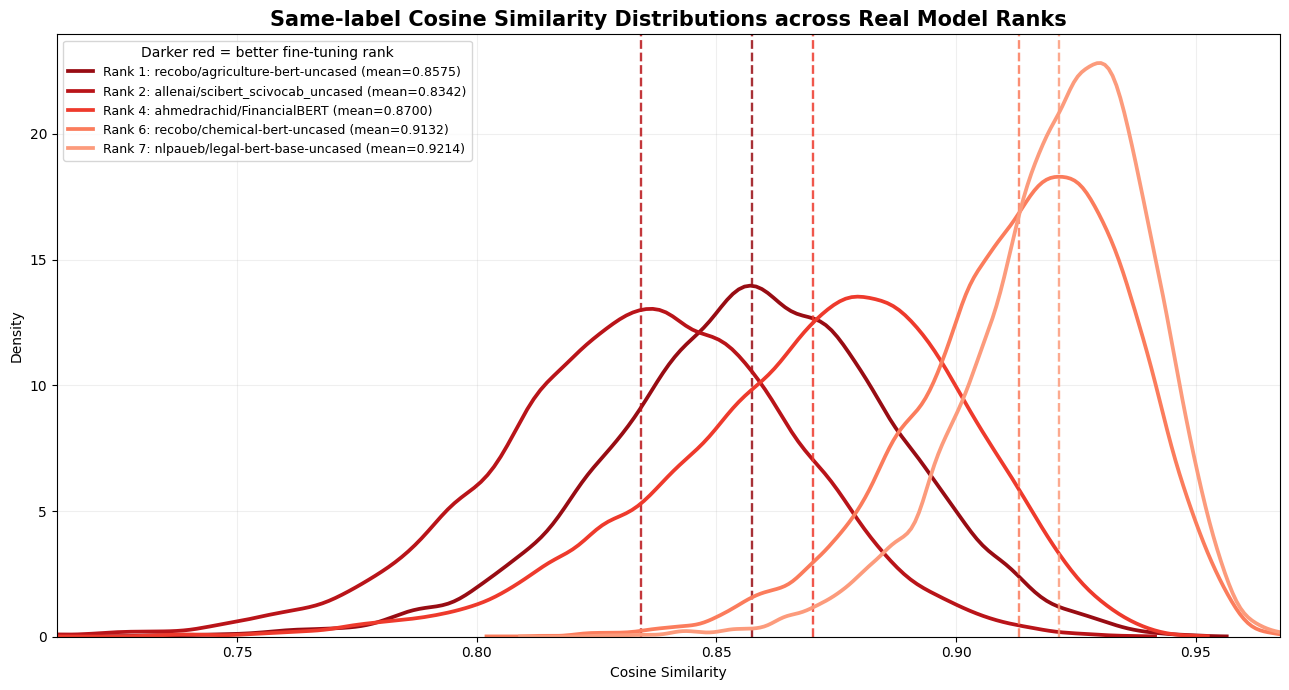

In [ ]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "same_scores"
    ]

    mean_value = values[
        "same_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Same-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker red = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    "ohsumed_same_label_rank_spanning.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

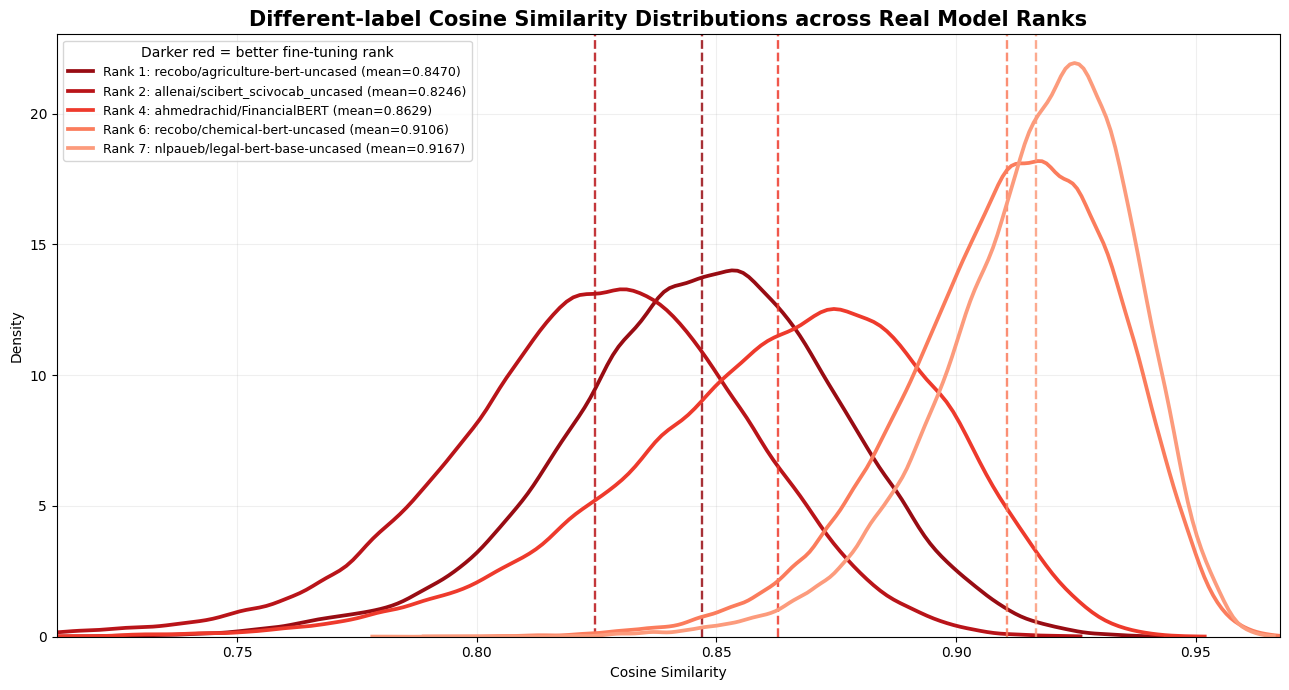

In [42]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "diff_scores"
    ]

    mean_value = values[
        "diff_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Different-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker red = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    (
        "ohsumed_different_label_"
        "rank_spanning.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()